# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [3]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [4]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [5]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [6]:
numbers = list(range(10))  # список для shuffle

def generate():
    number = random.randint(1, 100)
    shuffled = numbers.copy()
    random.shuffle(shuffled)
    print("randint:", number)
    print("shuffle:", shuffled)


# TODO: двічі ДО set_seed()
print("TODO: двічі ДО set_seed()")
generate()
generate()


random.seed(SEED)
print("Seed зафіксовано:", SEED)


# TODO: тепер двічі ПІСЛЯ set_seed()
# виклич set_seed() перед КОЖНИМ окремим генеруванням
print("TODO: тепер двічі ПІСЛЯ set_seed()")
random.seed(SEED)
generate()

random.seed(SEED)
generate()


# TODO: тепер ще двічі без проміжних викликів set_seed()
print("TODO: тепер ще двічі без проміжних викликів set_seed()")
generate()
generate()


TODO: двічі ДО set_seed()
randint: 93
shuffle: [8, 9, 4, 5, 6, 0, 3, 1, 7, 2]
randint: 73
shuffle: [8, 3, 1, 7, 6, 9, 0, 2, 4, 5]
Seed зафіксовано: 42
TODO: тепер двічі ПІСЛЯ set_seed()
randint: 82
shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
randint: 82
shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
TODO: тепер ще двічі без проміжних викликів set_seed()
randint: 76
shuffle: [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]
randint: 92
shuffle: [5, 1, 9, 0, 2, 4, 7, 3, 6, 8]


### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [7]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cuda
Використовуємо     : cpu
GPU: Tesla T4


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [8]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [9]:
# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print("З масиву 0")
print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)

print("З масиву 7")
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


З масиву 0
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
З масиву 7
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [10]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print("від 0 до 20 із кроком 2")
print(arange_arr)

print("5 рівномірно розподілених точок від 0 до 1")
print(linspace_arr)


від 0 до 20 із кроком 2
[ 0  2  4  6  8 10 12 14 16 18]
5 рівномірно розподілених точок від 0 до 1
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [11]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print("одинична матрицю 4×4")
print(identity)

print("Випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10)")
print(random_ints)


одинична матрицю 4×4
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10)
[[8 5 2]
 [8 8 7]
 [1 1 1]]


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [12]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [13]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)

matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [14]:
df = pd.DataFrame({
    "name": ["Артем", "Богдан", "Василь", "Вадим"],
    "score": [78, 95, 83, 91]
}) # додай тут дані для DataFrame

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df["score"] > 80].sort_values("score", ascending=False)
print(top)


     name  score
1  Богдан     95
3   Вадим     91
2  Василь     83


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [15]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
df["grade"] = np.select(
    [
        df["score"] >= 90,
        df["score"] >= 75
    ],
    [
        "A",
        "B"
    ],
    default="C"
)

print(df)


     name  score grade
0   Артем     78     B
1  Богдан     95     A
2  Василь     83     B
3   Вадим     91     A


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [16]:
# TODO: zeros_t = torch.zeros((2, 3))
# TODO: sevens_t = torch.full((2, 3), 7)
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print("Тензор форми 2×3, заповнений нулями")
print(zeros_t)

print("Заповнений числом 7")
print(sevens_t)


Тензор форми 2×3, заповнений нулями
tensor([[0., 0., 0.],
        [0., 0., 0.]])
Заповнений числом 7
tensor([[7, 7, 7],
        [7, 7, 7]])


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [17]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print("Тензор від 0 до 20 із кроком 2")
print(arange_t)

print("Тензор із 5 рівномірно розподілених точок від 0 до 1")
print(linspace_t)


Тензор від 0 до 20 із кроком 2
tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
Тензор із 5 рівномірно розподілених точок від 0 до 1
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [18]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print("Тензор напряму зі списку")
print(from_list)
print("shape:", from_list.shape)
print("dtype:", from_list.dtype)
print("ndim:", from_list.ndim)

print("\nВипадковий тензор форми 3×3")
print(random_t)
print("shape:", random_t.shape)
print("dtype:", random_t.dtype)
print("ndim:", random_t.ndim)


Тензор напряму зі списку
tensor([[1, 2],
        [3, 4]])
shape: torch.Size([2, 2])
dtype: torch.int64
ndim: 2

Випадковий тензор форми 3×3
tensor([[0.7392, 0.1277, 0.4859],
        [0.8210, 0.0940, 0.3482],
        [0.4572, 0.6938, 0.6935]])
shape: torch.Size([3, 3])
dtype: torch.float32
ndim: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [19]:
n = 5.0

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n

x = torch.tensor(5.0, requires_grad=True)
y = x ** 2

y.backward()

print("Автоматичний градієнт:", x.grad.item())

# dy/dx = 2x
analytical_grad = 2 * x.item()
print("Аналітичний градієнт:", analytical_grad)




Автоматичний градієнт: 10.0
Аналітичний градієнт: 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [20]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()

for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()

    with torch.no_grad():
        x -= lr * x.grad

    x.grad.zero_()



print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

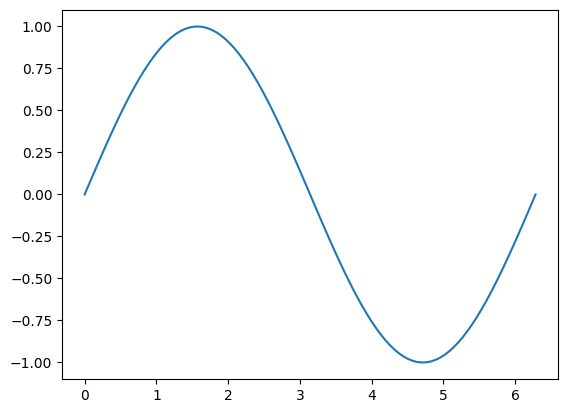

In [21]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()

xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))

plt.show()



**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

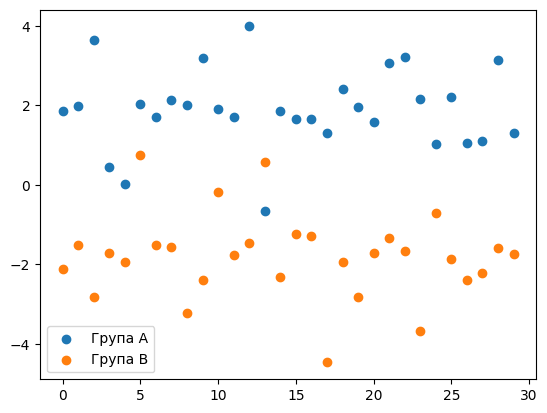

In [22]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()

plt.scatter(range(30), group_a, color="C0", label="Група A")
plt.scatter(range(30), group_b, color="C1", label="Група B")

plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [23]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

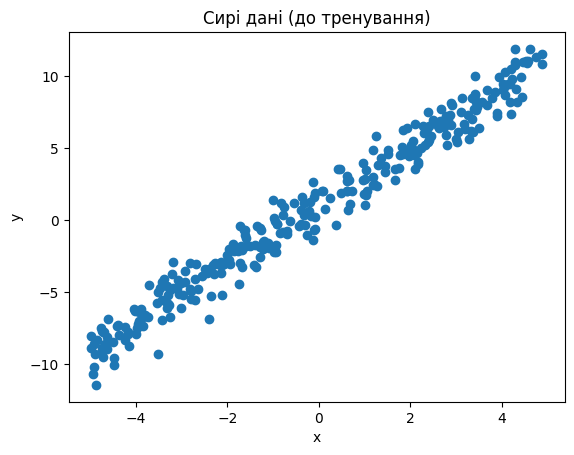

In [24]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"

plt.scatter(x1.numpy(), y1.numpy())

plt.xlabel("x")
plt.ylabel("y")
plt.title("Сирі дані (до тренування)")

plt.show()


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [25]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...

perm = torch.randperm(TASK1_N)

x1_shuffled = x1[perm]
y1_shuffled = y1[perm]

train_end = int(0.70 * TASK1_N)
val_end = train_end + int(0.15 * TASK1_N)

x_train1 = x1_shuffled[:train_end]
y_train1 = y1_shuffled[:train_end]

x_val1 = x1_shuffled[train_end:val_end]
y_val1 = y1_shuffled[train_end:val_end]

x_test1 = x1_shuffled[val_end:]
y_test1 = y1_shuffled[val_end:]


print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [26]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=65.939362  w=1.3187 (true 2.0)  b=-0.8097 (true 1.0)
epoch   30  loss=1.044131  w=2.0041 (true 2.0)  b=0.9866 (true 1.0)
epoch   60  loss=1.035832  w=2.0067 (true 2.0)  b=1.0654 (true 1.0)
epoch   90  loss=1.035817  w=2.0068 (true 2.0)  b=1.0688 (true 1.0)
epoch   99  loss=1.035816  w=2.0068 (true 2.0)  b=1.0689 (true 1.0)


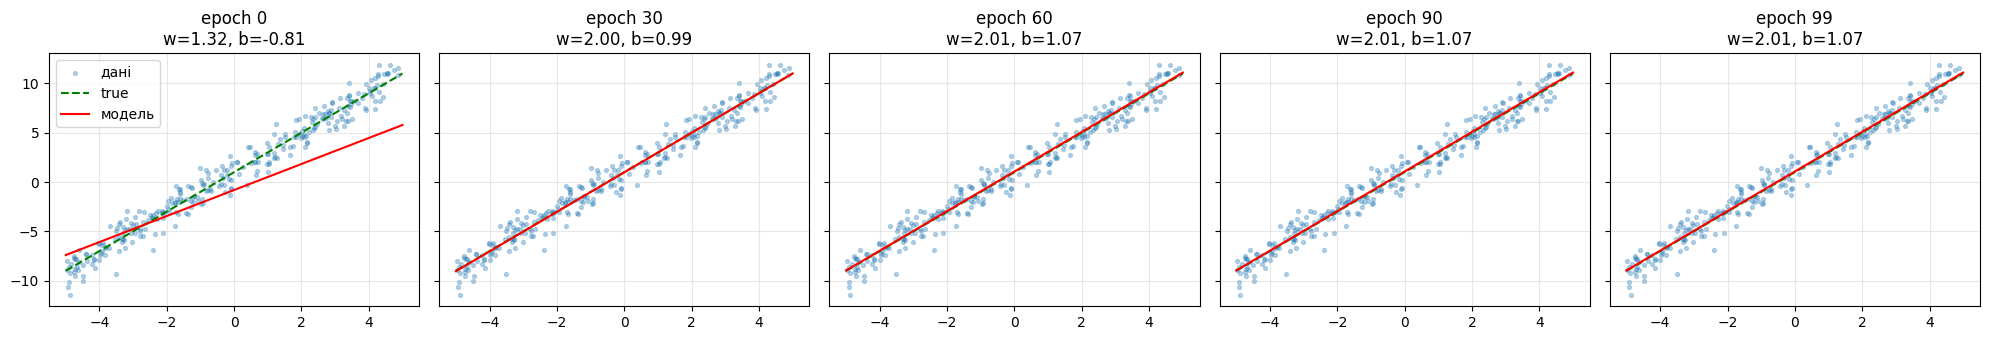

In [27]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Сценарій

Розглянемо умовну залежність максимальної швидкості автомобіля від його ціни у грі *Forza Horizon 5*. Вартість автомобілів у грі може суттєво відрізнятися: від приблизно 100 тисяч до кількох мільйонів кредитів. При цьому висока ціна не обов'язково означає вищу максимальну швидкість, оскільки рідкісні автомобілі можуть мати високу вартість через спосіб їх отримання або обмежену доступність.

Для навчального прикладу все ж припустимо спрощену лінійну залежність `y = wx + b`, де `x` — ціна автомобіля в мільйонах кредитів, а `y` — максимальна швидкість у км/год. Значення параметрів `w` і `b` будуть підібрані так, щоб згенеровані значення швидкості знаходилися приблизно в діапазоні 280–450 км/год. До даних буде додано випадковий шум, який імітуватиме відмінності між автомобілями та покаже, що ціна не визначає їхню максимальну швидкість однозначно.

Такий сценарій є напів-реальним: він використовує характеристики, характерні для гри, але саму лінійну залежність створено спеціально для демонстрації роботи моделі лінійної регресії.


In [30]:
from google.colab import drive

drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"

TASK2_N = 300
TASK2_TRUE_W = 30.0
TASK2_TRUE_B = 290.0

price = torch.empty(TASK2_N, 1).uniform_(0.1, 5.0)

noise = 15.0 * torch.randn(TASK2_N, 1)

speed = TASK2_TRUE_W * price + TASK2_TRUE_B + noise

df = pd.DataFrame({
    "price_million": price.squeeze().numpy(),
    "max_speed": speed.squeeze().numpy()
})

# Зберігаємо CSV на Google Drive
csv_path = f"{ARTIFACT_DIR}/dataset.csv"
df.to_csv(csv_path, index=False)

print(df.head())
print(f"\nДані збережено: {csv_path}")
print(f"Кількість автомобілів: {len(df)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   price_million   max_speed
0       0.149565  304.189758
1       2.165846  350.638824
2       1.412738  349.182983
3       4.826487  438.575531
4       2.669790  350.413025

Дані збережено: /content/drive/MyDrive/ai_systems/lab1/dataset.csv
Кількість автомобілів: 300


In [44]:
#Зчитуємо дані
df = pd.read_csv(f"{ARTIFACT_DIR}/dataset.csv")

x = torch.tensor(df["price_million"].values, dtype=torch.float32).unsqueeze(1)
y = torch.tensor(df["max_speed"].values, dtype=torch.float32).unsqueeze(1)

print(df.head())
print(f"Кількість даних: {len(df)}")

   price_million  max_speed
0       0.149565  304.18976
1       2.165846  350.63882
2       1.412738  349.18298
3       4.826487  438.57553
4       2.669790  350.41302
Кількість даних: 300


In [48]:
def split_data(x, y, train_ratio=0.70, val_ratio=0.15):
    n = len(x)

    perm = torch.randperm(n)

    x_shuffled = x[perm]
    y_shuffled = y[perm]

    train_end = int(train_ratio * n)
    val_end = train_end + int(val_ratio * n)

    x_train = x_shuffled[:train_end]
    y_train = y_shuffled[:train_end]

    x_val = x_shuffled[train_end:val_end]
    y_val = y_shuffled[train_end:val_end]

    x_test = x_shuffled[val_end:]
    y_test = y_shuffled[val_end:]

    return x_train, y_train, x_val, y_val, x_test, y_test



x_train, y_train, x_val, y_val, x_test, y_test = split_data(x, y)
print(f"train/val/test: {len(x_train)}/{len(x_val)}/{len(x_test)}")


train/val/test: 210/45/45


epoch    0  loss=134327.609375  w=92.1825  b=35.3969
epoch   30  loss=4143.523926  w=69.3541  b=167.6371
epoch   60  loss=1130.185303  w=49.6168  b=229.2093
epoch   90  loss=416.897583  w=40.0141  b=259.1659
epoch   99  loss=339.261749  w=38.2455  b=264.6832


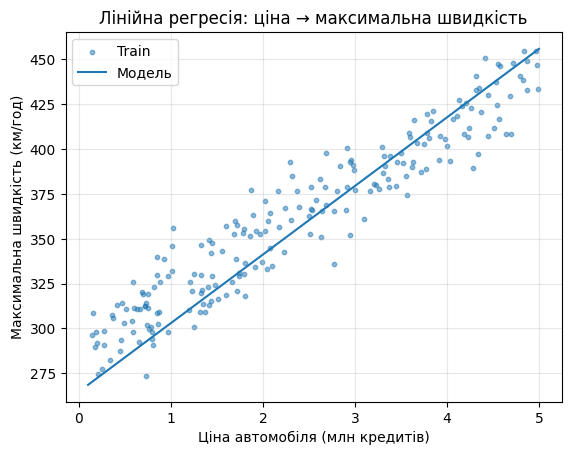

In [51]:
def train_model(x_train, y_train, epochs=100, lr=0.05):
    model = torch.nn.Linear(in_features=1, out_features=1)

    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    for epoch in range(epochs):
        optimizer.zero_grad()

        y_pred = model(x_train)
        loss = loss_fn(y_pred, y_train)

        loss.backward()
        optimizer.step()

        if epoch % 30 == 0 or epoch == epochs - 1:
            print(
                f"epoch {epoch:4d}  "
                f"loss={loss.item():.6f}  "
                f"w={model.weight.item():.4f}  "
                f"b={model.bias.item():.4f}"
            )

    return model


model = train_model(x_train, y_train)

x_line = torch.linspace(0.1, 5.0, 100).unsqueeze(1)

with torch.no_grad():
    y_line_pred = model(x_line)

plt.scatter(x_train.numpy(), y_train.numpy(), s=10, alpha=0.5, label="Train")
plt.plot(x_line.numpy(), y_line_pred.numpy(), label="Модель")

plt.xlabel("Ціна автомобіля (млн кредитів)")
plt.ylabel("Максимальна швидкість (км/год)")
plt.title("Лінійна регресія: ціна → максимальна швидкість")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [50]:
def evaluate_model(model, x_test, y_test):
    loss_fn = torch.nn.MSELoss()

    with torch.no_grad():
        y_pred = model(x_test)
        test_loss = loss_fn(y_pred, y_test)

    return test_loss.item()


test_loss = evaluate_model(model, x_test, y_test)
print(f"Test MSE: {test_loss:.6f}")

Test MSE: 406.992737


**Вправа 21.**

Збережи натреновану модель на своєму гугл диску у файлі з назвою model.pt. Збережений файл потрібно буде також здати разом з лабою.

In [53]:
#Збереження в файл

model_path = f"{ARTIFACT_DIR}/model.pt"
torch.save(model.state_dict(), model_path)

print(f"Модель збережено: {model_path}")

Модель збережено: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [54]:
!pip install -q gradio

#Gradio
import torch
import gradio as gr

model_path = f"{ARTIFACT_DIR}/model.pt"

model = torch.nn.Linear(1, 1)
model.load_state_dict(torch.load(model_path))
model.eval()
print("Модель успішно завантажено!")

def predict_speed(price):
    x = torch.tensor([[price]], dtype=torch.float32)

    with torch.no_grad():
        prediction = model(x)

    return prediction.item()


app = gr.Interface(
    fn=predict_speed,
    inputs=gr.Number(
        label="Ціна автомобіля (млн кредитів)",
        value=1.0
    ),
    outputs=gr.Number(
        label="Прогнозована максимальна швидкість (км/год)"
    ),
    title="Прогноз максимальної швидкості автомобіля",
    description="Введіть ціну автомобіля в мільйонах кредитів."
)

app.launch()

Модель успішно завантажено!
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f53b0489fd1a79d92e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```